In [1]:

from google.colab import files
import pandas as pd

# Upload the SMSSpamCollection file
uploaded = files.upload()

# Load the actual UCI dataset
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1"
)

print("Total messages:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nSample dataset records:")
display(df.head(10))


Saving SMSSpamCollection to SMSSpamCollection
Total messages: 5572

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Sample dataset records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [2]:

# PART 2: Dataset Analysis

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Messages:")
print(df.duplicated().sum())

print("\nDataset Information:")
print(df.info())

print("\nSample Spam Messages:")
display(df[df["label"] == "spam"].head(5))

print("\nSample Ham Messages:")
display(df[df["label"] == "ham"].head(5))


Dataset Shape: (5572, 2)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Messages:
403

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Sample Spam Messages:


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."



Sample Ham Messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...


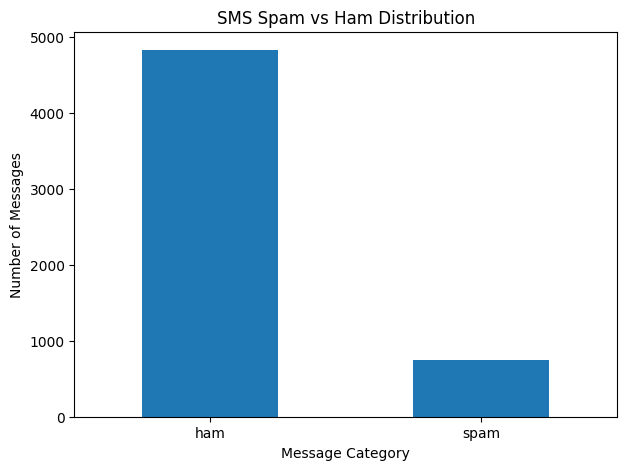

label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:

# PART 3: Spam vs Ham Visualization

import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")
plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

print(label_counts)


In [4]:

# PART 4: Data Preparation

from sklearn.model_selection import train_test_split

# Convert labels into numerical values
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

X = df["message"]
y = df["target"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Data preparation completed!")


Training Samples: 4457
Testing Samples: 1115
Data preparation completed!


In [5]:

# PART 5: Model Training

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# Create the machine learning pipeline
model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=1.0))
])

# Train the model
model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")


Naive Bayes Model Trained Successfully!


In [6]:

# PART 6: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict test data
y_pred = model.predict(X_test)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))


MODEL PERFORMANCE
-------------------------
Accuracy: 98.74 %
Precision: 0.9856
Recall: 0.9195
F1 Score: 0.9514

Detailed Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



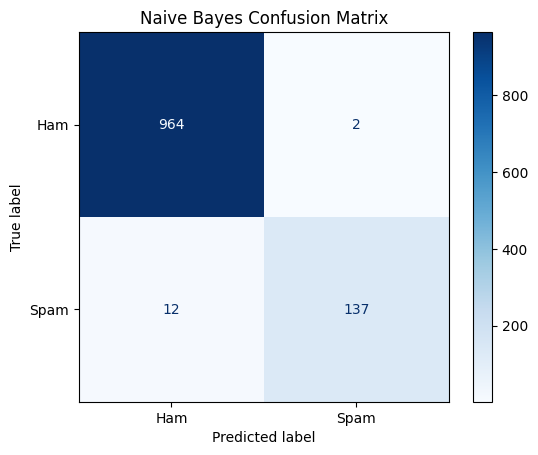

Confusion Matrix:
[[964   2]
 [ 12 137]]


In [7]:

# PART 7: Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display_matrix.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [8]:

# PART 8: Correct and Incorrect Predictions

results = pd.DataFrame({
    "Actual": y_test.map({0: "Ham", 1: "Spam"}),
    "Predicted": pd.Series(y_pred, index=y_test.index)
        .map({0: "Ham", 1: "Spam"}),
    "Message": X_test
})

results["Correct"] = results["Actual"] == results["Predicted"]

print("CORRECT PREDICTIONS:")
display(results[results["Correct"]].head(3))

print("INCORRECT PREDICTIONS:")
display(results[~results["Correct"]].head(3))


CORRECT PREDICTIONS:


,Actual,Predicted,Message,Correct
2825,Ham,Ham,No need to buy lunch for me.. I eat maggi mee..,True
3695,Ham,Ham,Ok im not sure what time i finish tomorrow but...,True
3904,Ham,Ham,Waiting in e car 4 my mum lor. U leh? Reach ho...,True


INCORRECT PREDICTIONS:


,Actual,Predicted,Message,Correct
5,Spam,Ham,FreeMsg Hey there darling it's been 3 week's n...,False
3360,Spam,Ham,Sorry I missed your call let's talk when you h...,False
5449,Spam,Ham,"Latest News! Police station toilet stolen, cop...",False


In [9]:

# PART 9: Test New SMS Messages

new_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash reward. Claim it now!",
    "Can you please send me the notes from class?"
]

predictions = model.predict(new_messages)

for message, prediction in zip(new_messages, predictions):
    category = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", category)
    print("-----------------------------")


Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
-----------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM
-----------------------------
Message: URGENT! You have won a cash reward. Claim it now!
Prediction: SPAM
-----------------------------
Message: Can you please send me the notes from class?
Prediction: HAM
-----------------------------


In [10]:

# PART 10: Generate README and requirements files

readme = f"""
# SMS Spam Filtering Using Naive Bayes

## Machine Learning CLA-3 Case Study

**Student:** Rayankula Mounish
**Roll Number:** AP24110011534

## Objective
To classify SMS messages as Spam or Ham using
Multinomial Naive Bayes.

## Dataset
UCI SMS Spam Collection Dataset

Total Messages: {len(df)}
Ham Messages: {(df["label"] == "ham").sum()}
Spam Messages: {(df["label"] == "spam").sum()}

## Algorithm
- CountVectorizer
- Multinomial Naive Bayes

## Model Evaluation
Accuracy: {accuracy * 100:.2f}%
Precision: {precision:.4f}
Recall: {recall:.4f}
F1 Score: {f1:.4f}

## Tools Used
- Python
- Google Colab
- Pandas
- Scikit-learn
- Matplotlib

See the Jupyter Notebook for the complete implementation
and experimental results.
"""

with open("README.md", "w") as f:
    f.write(readme)

with open("requirements.txt", "w") as f:
    f.write("pandas\nmatplotlib\nscikit-learn\n")

print("README.md created!")
print("requirements.txt created!")


README.md created!
requirements.txt created!
